# Final project: Is this tweet ironic?

People say the opposite of what they mean all the time: "Great, another Monday." A human reader catches it in a second. A computer sees seven ordinary words. Teaching a program to notice the gap between what is said and what is meant is one of the hardest problems in natural language processing, and it is your final project.

**The task.** You get a file of tweets, each labelled *ironic* (1) or *not ironic* (0). You build a model that predicts the label of tweets it has never seen. Your predictions on a hidden test set are graded, together with how you got there: your exploration, your experiments, your error analysis and your report.

**What you hand in.** This notebook, completed and run from top to bottom, and the file `submission.csv` that section 9 writes. The one-page guidelines (`guidelines.pdf`) list the rules and how points are awarded.

**How the notebook is organised.** Sections 1 to 6 are given: they load the data, set the evaluation rules and build a baseline that works. Your work starts in section 3 (exploration), continues in section 7 (your models) and section 8 (error analysis), and ends with section 10 (your report). Cells marked `TODO` are yours. Everything else runs as it is, so you always start from a pipeline that works.

## How to run this notebook

- **Locally (Jupyter or VS Code):** open this file from the project folder (the one that holds `data/`), with the packages in `requirements.txt` installed, and run the cells top to bottom.
- **Google Colab:** open this notebook from the course repository with the Colab badge in the README, or upload it (File > Upload notebook). When the setup cell does not find `data/train.csv` and `data/test.csv` next to the notebook it downloads them from the course repository on GitHub; if that fails, it asks you to upload the two files. Colab's free GPU is only needed for the optional transformer idea in section 7.

Everything in sections 1 to 9 runs on a laptop CPU in a few minutes. Random operations use `SEED = 42`, so the given cells print the same numbers every time.

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2a78d6", "#9aa5b1"

DATA = Path("data")
needed = [DATA / "train.csv", DATA / "test.csv"]
REPO_DATA = "https://raw.githubusercontent.com/maglionejm/fontys-tech-exercises/main/M4%20-%20Natural%20Language%20Processing/data/"
if not all(p.exists() for p in needed):           # not run from the module folder (Colab, a copy elsewhere): fetch the data
    import urllib.request
    DATA.mkdir(exist_ok=True)
    try:
        for p in needed:
            urllib.request.urlretrieve(REPO_DATA + p.name, p)
        print("Downloaded train.csv and test.csv from the course repository.")
    except Exception as error:                   # offline or the files moved: fall back to a manual upload on Colab
        print(f"Download failed ({error.__class__.__name__}).")
        if "google.colab" in sys.modules:
            from google.colab import files
            print("Upload train.csv and test.csv from the course's data/ folder:")
            for name, content in files.upload().items():
                (DATA / Path(name).name).write_bytes(content)
missing = [p.name for p in needed if not p.exists()]
assert not missing, f"missing {missing}: run this notebook from the module folder, or put the files in data/"

print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("data files found:", ", ".join(p.name for p in needed))

python 3.14.7 | pandas 3.0.6 | scikit-learn 1.9.1
data files found: train.csv, test.csv


## 1. The challenge

> **Irony**, in plain words: saying one thing while meaning another, usually the opposite, and counting on the reader to notice. *Sarcasm* is irony with an edge, aimed at someone. In this project the two are treated as one class, *ironic*, because that is how the dataset was labelled.

Why is this hard for a program? Because the words in an ironic tweet are often perfectly positive ("great", "love", "perfect") while the meaning is negative. The signal is in the **gap**: a positive word next to a bad situation, an exaggeration, a hashtag that undercuts the sentence, an exclamation mark too many. A model that only counts words sees the surface. Your job is to find features and models that see the gap.

**The data.** The tweets come from the SemEval-2018 shared task on irony detection (Van Hee, Lefever and Hoste, 2018). The authors collected tweets that their writers had tagged with the hashtags `#irony`, `#sarcasm` or `#not`, removed those three hashtags from the text, and had three linguists annotate every tweet as ironic or not; they then added non-ironic tweets to balance the classes. The same corpus is part of the TweetEval benchmark (Barbieri et al., 2020) and is published on Kaggle in the TweetEval dataset. For this course the corpus was pooled, de-duplicated and split once with a fixed seed:

| File | Tweets | Columns | Your use |
|---|---|---|---|
| `data/train.csv` | 3,450 | `id, text, label` | explore, train, validate |
| `data/test.csv` | 1,151 | `id, text` | predict; the labels are hidden and used for grading |

User names were replaced by `@user` and web links by `http` before the data was published. Hashtags, emoji, capitals and punctuation were kept; think about whether to keep them too.

**The metric.** Your submission is scored with **macro-F1**, the average of the F1 score of the ironic class and the F1 score of the non-ironic class, so both classes count equally. Accuracy is reported as well. Section 5 explains F1 in plain words and gives you the code.

**The rule that matters most.** You never see the test labels. Every decision you make (which features, which model, which settings) must be made on data you split off from `train.csv`. That is how models are evaluated in practice, and it is what section 5 sets up.

## 2. Load the data

Two files, read with pandas. Look at the first rows and the column types before anything else: a surprising number of projects fail on a column that is not what the author assumed.

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

assert list(train.columns) == ["id", "text", "label"], train.columns
assert list(test.columns) == ["id", "text"], test.columns
assert set(train["label"].unique()) == {0, 1}

print(f"train: {len(train):,} tweets | test: {len(test):,} tweets (no labels)")
train.head()

train: 3,450 tweets | test: 1,151 tweets (no labels)


,id,text,label
0,tr0000,..and another #freelesson #english #esl #tesl...,1
1,tr0001,Do you use Instagram? Well get 100 free follow...,0
2,tr0002,Is your internet a bit slow today? Blame a thi...,0
3,tr0003,Great way to start of the day,1
4,tr0004,"#Ukraine's #President to #meet #Russian, #Fren...",0


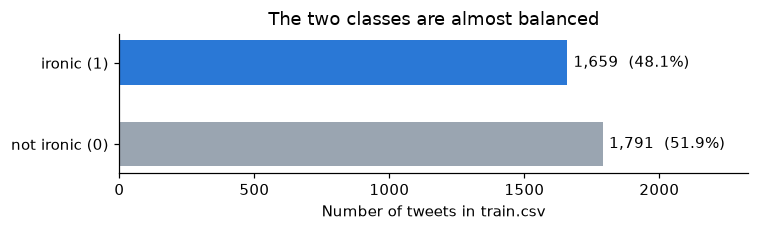

In [3]:
counts = train["label"].value_counts().sort_index()
share = counts / counts.sum()

fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(["not ironic (0)", "ironic (1)"], counts.values, color=[GREY, BLUE], height=0.55)
ax.bar_label(bars, labels=[f"{c:,}  ({s:.1%})" for c, s in zip(counts.values, share.values)], padding=4)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_xlabel("Number of tweets in train.csv")
ax.set_title("The two classes are almost balanced")
plt.tight_layout()
plt.show()

**How to read it:** one bar per class, the length is the number of training tweets with that label. The classes are close to balanced, so a model that always says "not ironic" gets about half of the tweets right and nothing more. Balanced classes also mean that accuracy and macro-F1 will move together here; on the original SemEval test set, where only 40% of tweets were ironic, they did not, which is why the shared task used F1.

Before any statistics, read some tweets. Six are printed below without their labels. Decide for each one whether it is ironic, then run the next cell to see the labels. This tells you how hard the task is for a human who, unlike the model, understands every word.

In [4]:
quiz = train.sample(6, random_state=SEED).reset_index(drop=True)
for i, text in enumerate(quiz["text"], start=1):
    print(f"{i}. {text}")

1. Some #tblightning action along the boards at @user in #Tampa #fuji #x30 #boltssocial #bethethunder
2. I have plans. I feel sick. What a surprising turn of events.
3. @user the word itself is a mockery .... Bae ...like abey 😣
4. @user @user We must be tolerant and embrace the peaceful Islamic faith, Muslims are our peaceful brothers
5. #QZ8501 asks permission to #takeoff: #towercontrol of #Surubaya: yeah..y can go...away.
6. Monday mornings are my fave :)


In [5]:
for i, (text, label) in enumerate(zip(quiz["text"], quiz["label"]), start=1):
    print(f"{i}. {'IRONIC    ' if label == 1 else 'not ironic'} | {text[:90]}")

1. not ironic | Some #tblightning action along the boards at @user in #Tampa #fuji #x30 #boltssocial #beth
2. IRONIC     | I have plans. I feel sick. What a surprising turn of events.
3. not ironic | @user the word itself is a mockery .... Bae ...like abey 😣
4. IRONIC     | @user @user We must be tolerant and embrace the peaceful Islamic faith, Muslims are our pe
5. not ironic | #QZ8501 asks permission to #takeoff: #towercontrol of #Surubaya: yeah..y can go...away.
6. IRONIC     | Monday mornings are my fave :)


## 3. Explore the text (TODO)

> **Exploratory analysis**, in plain words: looking at the data from several angles before modelling, so that your choices later are informed rather than guessed.

Two starter analyses are given. The first measures simple surface properties per class: how long tweets are and how often they contain a hashtag, a mention, an exclamation mark, a question mark, a word in capitals or a character outside the basic alphabet (emoji, mostly). The second finds the words that are most typical of each class.

,not ironic,ironic
words,13.668,13.777
has hashtag,0.433,0.463
has @user,0.455,0.312
has !,0.160,0.165
has ?,0.121,0.095
has CAPS word,0.126,0.101
has emoji / non-ascii,0.130,0.102


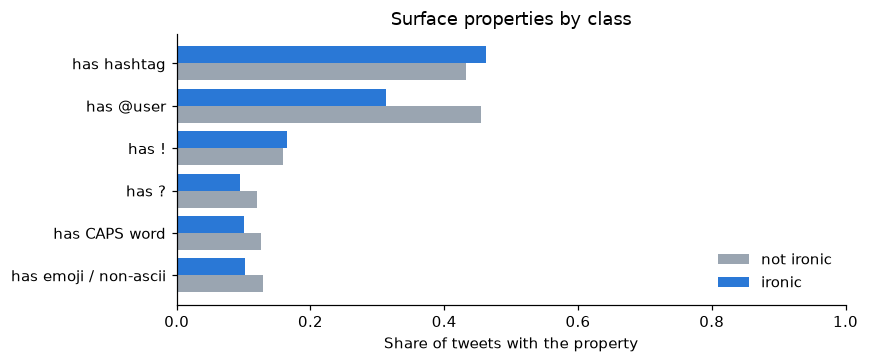

In [6]:
def surface(text: str) -> dict:
    """Simple surface properties of one tweet; each is a number a model could use."""
    words = text.split()
    return {
        "words": len(words),
        "has hashtag": "#" in text,
        "has @user": "@user" in text,
        "has !": "!" in text,
        "has ?": "?" in text,
        "has CAPS word": any(w.isupper() and len(w) > 1 and w.isalpha() for w in words),
        "has emoji / non-ascii": any(ord(c) > 127 for c in text),
    }

feats = pd.DataFrame([surface(t) for t in train["text"]])
feats["label"] = train["label"].values
summary = feats.groupby("label").mean().T
summary.columns = ["not ironic", "ironic"]
display(summary.round(3))

rates = summary.drop(index="words")
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(rates))
ax.barh(y + 0.2, rates["not ironic"], height=0.4, color=GREY, label="not ironic")
ax.barh(y - 0.2, rates["ironic"], height=0.4, color=BLUE, label="ironic")
ax.set_yticks(y, rates.index)
ax.invert_yaxis()
ax.set_xlabel("Share of tweets with the property")
ax.set_xlim(0, 1)
ax.set_title("Surface properties by class")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**How to read it:** each pair of bars is one property; the length is the share of tweets in that class that have it. Where the two bars differ, the property carries information about irony; where they are equal, it does not. The table above the chart adds the mean length in words.

The second starter finds words that are **typical of one class**: for each word that appears at least 10 times, it compares how often the word occurs in ironic tweets with how often it occurs in non-ironic ones (with a small smoothing count so that rare words do not dominate).

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b|#\w+", min_df=10)
X_counts = cv.fit_transform(train["text"])
vocab = np.array(cv.get_feature_names_out())
is_irony = train["label"].values == 1
ironic_counts = np.asarray(X_counts[is_irony].sum(axis=0)).ravel()
other_counts = np.asarray(X_counts[~is_irony].sum(axis=0)).ravel()
ratio = (ironic_counts + 1) / (ironic_counts.sum() + len(vocab)) / ((other_counts + 1) / (other_counts.sum() + len(vocab)))
order = np.argsort(ratio)

def show(indices, title):
    print(title)
    for i in indices:
        print(f"   {vocab[i]:<18} ironic {ironic_counts[i]:>4}   not ironic {other_counts[i]:>4}   ratio {ratio[i]:.2f}")

show(order[::-1][:15], "Words most typical of IRONIC tweets (ratio > 1):")
print()
show(order[:15], "Words most typical of NOT ironic tweets (ratio < 1):")

Words most typical of IRONIC tweets (ratio > 1):
   far                ironic   10   not ironic    0   ratio 11.27
   waking             ironic   19   not ironic    1   ratio 10.24
   yay                ironic   26   not ironic    2   ratio 9.22
   #irony             ironic   70   not ironic   10   ratio 6.61
   fun                ironic   54   not ironic    8   ratio 6.26
   fix                ironic    9   not ironic    1   ratio 5.12
   wonderful          ironic   13   not ironic    2   ratio 4.78
   glad               ironic   17   not ironic    3   ratio 4.61
   hour               ironic   12   not ironic    2   ratio 4.44
   #sarcasm           ironic   68   not ironic   15   ratio 4.42
   great              ironic   77   not ironic   18   ratio 4.20
   wow                ironic   22   not ironic    5   ratio 3.93
   final              ironic   14   not ironic    3   ratio 3.84
   monday             ironic   13   not ironic    3   ratio 3.58
   super              ironic   13   not

**Your exploration (TODO).** Add at least two analyses of your own and write one or two sentences under each about what you see. Ideas, from easy to harder:

- Which hashtags are most frequent in each class? (Hint: `re.findall(r"#\w+", text)`.)
- Do ironic tweets use more exclamation marks, more ellipses (`...`), more emoji? Count per tweet, not just presence.
- Are the typical words above *positive* words? Compare them with a small list of positive and negative words you write yourself.
- Is tweet length (in characters) distributed differently per class? Plot it.
- Pick 20 ironic tweets at random and sort them by hand into the kinds of irony you see (positive words about a bad situation, exaggeration, a hashtag that reverses the meaning, situational irony with no clue in the words). Which kind do you expect a word-counting model to miss?

The starter below counts exclamation marks per class; replace or extend it.

In [8]:
# TODO: your exploration. The starter counts exclamation marks per tweet and compares the classes.
train["n_exclamation"] = train["text"].str.count("!")
print(train.groupby("label")["n_exclamation"].agg(["mean", "max"]).rename(index={0: "not ironic", 1: "ironic"}))

# Your analyses here (add cells as you need them).


                mean  max
label                    
not ironic  0.253490    7
ironic      0.299578   19


## 4. Preprocessing: what to keep and what to throw away

> **Preprocessing**, in plain words: turning raw text into the pieces a model counts. The usual recipe is lowercase everything, split into words, drop punctuation and very common words.

For irony, think twice before applying the usual recipe. Capital letters (`SO fun`), punctuation (`great...`, `fun!!!`), emoji and hashtags are exactly the places where writers signal that they do not mean what they say. The function below gives you switches for each choice so that you can test, in section 7, whether keeping them helps. Note also that the default tokenizer of scikit-learn's vectorizers, `(?u)\b\w\w+\b`, silently drops one-letter words, punctuation and emoji; you can pass your own `token_pattern`.

In [9]:
def clean_text(text: str, lower: bool = True, keep_hashtags: bool = True,
               keep_mentions: bool = False, keep_punct: bool = True) -> str:
    """Light cleaning with explicit choices. Every switch is an experiment waiting to happen."""
    out = text
    if not keep_mentions:
        out = out.replace("@user", " ")
    out = out.replace("http", " ")                       # links were already replaced by the word http
    if not keep_hashtags:
        out = re.sub(r"#\w+", " ", out)
    else:
        out = re.sub(r"#(\w+)", r"\1 #\1", out)          # keep the hashtag and also its word: '#blessed' -> 'blessed #blessed'
    if not keep_punct:
        out = re.sub(r"[^\w\s]", " ", out)
    if lower:
        out = out.lower()
    return re.sub(r"\s+", " ", out).strip()

for text in train["text"].head(3):
    print("raw:    ", text)
    print("cleaned:", clean_text(text))
    print()

raw:     ..and another  #freelesson #english #esl #tesl @user
cleaned: ..and another freelesson #freelesson english #english esl #esl tesl #tesl

raw:     Do you use Instagram? Well get 100 free followers at -- No.
cleaned: do you use instagram? well get 100 free followers at -- no.

raw:     Is your internet a bit slow today? Blame a thick, wet, cable:
cleaned: is your internet a bit slow today? blame a thick, wet, cable:



## 5. The rules of evaluation

> A **validation set**, in plain words: a slice of the labelled data that you keep aside and never train on, so that you can measure how the model does on tweets it has not seen. It stands in for the hidden test set.

The cell below splits `train.csv` into a **training part** (80%) and a **validation part** (20%), stratified so that both parts have the same share of ironic tweets, with the fixed seed. Fit models on the training part, measure on the validation part, choose on the validation part. When you are done choosing (section 9), refit the chosen model on all of `train.csv` and predict `test.csv`.

> **F1**, in plain words. For the ironic class, *precision* is the share of tweets the model called ironic that really were; *recall* is the share of truly ironic tweets the model found. F1 is the harmonic mean of the two: it is high only when both are high. **Macro-F1** computes F1 for each class and averages them, so a model that is good on one class and bad on the other is punished.

The helper `evaluate` returns accuracy, macro-F1, and precision, recall and F1 of the ironic class; `plot_confusion` draws the four counts behind those numbers.

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    train["text"], train["label"], test_size=0.2, random_state=SEED, stratify=train["label"])
print(f"training part: {len(X_train):,} tweets | validation part: {len(X_val):,} tweets | "
      f"ironic share {y_train.mean():.3f} vs {y_val.mean():.3f}")


def evaluate(y_true, y_pred) -> dict:
    """The numbers the project is graded on, in one dictionary."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "irony_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "irony_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "irony_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["predicted 0", "predicted 1"])
    ax.set_yticks([0, 1], ["true 0", "true 1"])
    ax.set_title(title, fontsize=10)
    ax.spines[:].set_visible(False)
    plt.tight_layout()
    plt.show()

training part: 2,760 tweets | validation part: 690 tweets | ironic share 0.481 vs 0.481


## 6. The baseline you must beat

Two baselines. The first predicts the majority class for every tweet: it is the floor, and anything that cannot beat it has learned nothing. The second is the classic text pipeline, in plain words:

- **TF-IDF** turns each tweet into a row of numbers, one per word (and per pair of adjacent words), where a word counts more when it is frequent in this tweet and rare across all tweets.
- **Logistic regression** learns one weight per word and adds them up: a positive total means "ironic". It is fast, hard to break and easy to inspect, which makes it the right first model.

The baseline uses the raw text, the default tokenizer and default settings on purpose. Your experiments in section 7 change one thing at a time and measure what it buys.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
majority_scores = evaluate(y_val, majority.predict(X_val))
print("majority class:", {k: round(v, 3) for k, v in majority_scores.items()})

majority class: {'accuracy': 0.519, 'macro_f1': 0.342, 'irony_precision': 0.0, 'irony_recall': 0.0, 'irony_f1': 0.0}


TF-IDF + logistic regression: {'accuracy': 0.638, 'macro_f1': 0.636, 'irony_precision': 0.63, 'irony_recall': 0.599, 'irony_f1': 0.614}


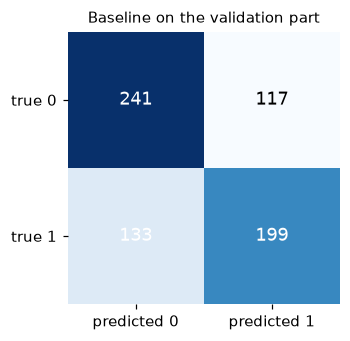

In [12]:
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000, random_state=SEED),
)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_val)
baseline_scores = evaluate(y_val, baseline_pred)
print("TF-IDF + logistic regression:", {k: round(v, 3) for k, v in baseline_scores.items()})
plot_confusion(y_val, baseline_pred, "Baseline on the validation part")

**How to read the confusion matrix:** rows are the truth, columns the prediction. The top-left and bottom-right cells are correct; the top-right cell holds non-ironic tweets the model called ironic (false alarms); the bottom-left holds ironic tweets it missed. Macro-F1 goes up when both off-diagonal cells go down.

One validation split is one measurement. With a few hundred validation tweets, a different split can move macro-F1 by a couple of points, so a difference between two models that is smaller than that is noise. **Cross-validation** repeats the experiment on five different splits and reports the mean and the spread; use it when two candidates are close.

In [13]:
cv_splits = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(baseline, train["text"], train["label"], cv=cv_splits, scoring="f1_macro")
print("baseline macro-F1, 5-fold cross-validation on all of train.csv:")
print("  folds:", np.round(cv_scores, 3), f"| mean {cv_scores.mean():.3f} | std {cv_scores.std():.3f}")

baseline macro-F1, 5-fold cross-validation on all of train.csv:
  folds: [0.667 0.662 0.649 0.661 0.664] | mean 0.661 | std 0.006


A linear model can be read. The weights below are the words that push the baseline most strongly towards "ironic" and towards "not ironic". Compare them with the typical words from section 3 and with your own intuition: does the model lean on meaning, or on topics that happen to be frequent in one class?

In [14]:
vectorizer, clf = baseline.named_steps["tfidfvectorizer"], baseline.named_steps["logisticregression"]
terms = np.array(vectorizer.get_feature_names_out())
weights = clf.coef_[0]
top = np.argsort(weights)
print("pushes towards IRONIC:     ", ", ".join(terms[top[::-1][:20]]))
print("pushes towards NOT ironic: ", ", ".join(terms[top[:20]]))

pushes towards IRONIC:      irony, great, love, fun, so, sarcasm, nice, yay, oh, thanks, well, thanks for, monday, job, wait, an, hours, joy, being, is
pushes towards NOT ironic:  user, long, 2015, you, but, make, tonight, do, first, go, hope, teenanalcasting, via, happy, check, rt, understand, would, girl, 2014


## 7. Your turn: build a better model (TODO)

This is the core of the project. Run **at least three experiments** beyond the two baselines, change **one thing at a time**, and log every run in the results table so that the comparison is honest. Fit on the training part, measure on the validation part; when two runs are close, confirm with cross-validation.

Ideas, roughly in order of effort:

1. **Features.** Character n-grams (`analyzer="char_wb"`) catch spelling, elongation (`sooo`), punctuation runs and emoji that word tokens miss. A custom `token_pattern` keeps `!`, `?` and emoji as tokens. `clean_text` from section 4 lets you test every preprocessing switch. Hand-made counts (exclamation marks, capitals, emoji, hashtags) can be appended with `FeatureUnion` or `ColumnTransformer`.
2. **Models.** `LinearSVC` and `MultinomialNB` are the usual rivals of logistic regression on sparse text. `class_weight="balanced"` trades precision for recall. Combining word and character features often beats either alone.
3. **Settings.** Regularisation strength `C`, `ngram_range`, `min_df`. Search them with `GridSearchCV` on the training part only (the grid search does its own cross-validation inside).
4. **Pretrained language models (optional, Colab GPU recommended).** Sentence embeddings (`sentence-transformers`) plus logistic regression, or fine-tuning a small transformer such as `distilroberta-base` or `cardiffnlp/twitter-roberta-base` with the `transformers` library. This is where the state of the art lives, and it is where the gains are. Two rules: declare the model in your report, and **never use a model that was already trained on this dataset** (for example `cardiffnlp/twitter-roberta-base-irony`), because it has seen the test tweets. A sketch of the fine-tuning code is given at the end of this section; it is not run here because it downloads a model and needs a GPU to finish in minutes.

The helper below runs an experiment and stores its scores and the fitted model. Experiment 1 is given, experiment 2 is a starter you should extend, experiment 3 is yours.

In [15]:
from sklearn.base import clone

results = {}     # name -> dict(scores, model, notes)


def run_experiment(name: str, model, notes: str = ""):
    """Fit on the training part, score on the validation part, log everything under `name`."""
    fitted = clone(model).fit(X_train, y_train)
    scores = evaluate(y_val, fitted.predict(X_val))
    results[name] = {"scores": scores, "model": fitted, "notes": notes}
    print(f"{name:<44} macro-F1 {scores['macro_f1']:.3f} | accuracy {scores['accuracy']:.3f} | "
          f"irony P {scores['irony_precision']:.2f} R {scores['irony_recall']:.2f}")
    return fitted


run_experiment("majority class", DummyClassifier(strategy="most_frequent"), "floor")
run_experiment("baseline: TF-IDF words 1-2 + LR", baseline, "raw text, default tokenizer");

majority class                               macro-F1 0.342 | accuracy 0.519 | irony P 0.00 R 0.00
baseline: TF-IDF words 1-2 + LR              macro-F1 0.636 | accuracy 0.638 | irony P 0.63 R 0.60


**Experiment 1 (given): character n-grams.** The vectorizer now counts sequences of 2 to 5 characters inside word boundaries instead of words. Spelling variants, repeated letters, punctuation and emoji all become features. The classifier is a linear support vector machine, which often edges out logistic regression on sparse text.

In [16]:
from sklearn.svm import LinearSVC

exp1 = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    LinearSVC(C=0.5, random_state=SEED),
)
run_experiment("exp1: TF-IDF chars 2-5 + LinearSVC", exp1, "character n-grams");

exp1: TF-IDF chars 2-5 + LinearSVC           macro-F1 0.663 | accuracy 0.664 | irony P 0.65 R 0.65


**Experiment 2 (starter, extend it): tune the settings honestly.** `GridSearchCV` tries every combination in the grid with 5-fold cross-validation *inside the training part*, so the validation part stays untouched until the end. Extend the grid (other `min_df`, `class_weight`, the character model) and keep the search time reasonable: the number of fits is the product of the grid sizes times five.

In [17]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    make_pipeline(TfidfVectorizer(sublinear_tf=True), LogisticRegression(max_iter=3000, random_state=SEED)),
    param_grid={
        "tfidfvectorizer__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "tfidfvectorizer__min_df": [1, 2],
        "logisticregression__C": [0.3, 1, 3, 10],
    },
    scoring="f1_macro", cv=cv_splits, n_jobs=-1,
)
grid.fit(X_train, y_train)
print("best settings:", grid.best_params_, f"| inner CV macro-F1 {grid.best_score_:.3f}")
run_experiment("exp2: tuned TF-IDF words + LR", grid.best_estimator_, f"grid search, {grid.best_params_}");

best settings: {'logisticregression__C': 3, 'tfidfvectorizer__min_df': 1, 'tfidfvectorizer__ngram_range': (1, 1)} | inner CV macro-F1 0.650
exp2: tuned TF-IDF words + LR                macro-F1 0.647 | accuracy 0.648 | irony P 0.64 R 0.61


**Experiment 3 (yours).** The starter combines word and character features, keeps punctuation and emoji as tokens through a custom `token_pattern`, and runs `clean_text` as the preprocessor. Replace it with your own idea, or use it as the base for several variants: switch one `clean_text` option, add hand-made features, try a different classifier. Each variant is one more line in the results table.

In [18]:
# TODO: replace or extend. One idea per experiment, one line per experiment in the results table.
from sklearn.pipeline import FeatureUnion

keep_punct_and_emoji = r"(?u)\b\w+\b|[!?.]{1,3}|[^\w\s]"
exp3 = make_pipeline(
    FeatureUnion([
        ("words", TfidfVectorizer(preprocessor=clean_text, token_pattern=keep_punct_and_emoji,
                                  ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("chars", TfidfVectorizer(preprocessor=clean_text, analyzer="char_wb",
                                  ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    ]),
    LogisticRegression(C=3, max_iter=3000, class_weight="balanced", random_state=SEED),
)
run_experiment("exp3: words+chars, punct/emoji tokens + LR", exp3, "clean_text preprocessor, balanced weights");

# Your experiments 4, 5, ... here.

exp3: words+chars, punct/emoji tokens + LR   macro-F1 0.671 | accuracy 0.671 | irony P 0.65 R 0.69


,accuracy,macro_f1,irony_precision,irony_recall,irony_f1,notes
"exp3: words+chars, punct/emoji tokens + LR",0.671,0.671,0.650,0.687,0.668,"clean_text preprocessor, balanced weights"
exp1: TF-IDF chars 2-5 + LinearSVC,0.664,0.663,0.652,0.648,0.650,character n-grams
exp2: tuned TF-IDF words + LR,0.648,0.647,0.640,0.611,0.626,"grid search, {'logisticregression__C': 3, 'tfidfvectorizer__min_df': 1, 'tfidfvectorizer__ngram_range': (1, 1)}"
baseline: TF-IDF words 1-2 + LR,0.638,0.636,0.630,0.599,0.614,"raw text, default tokenizer"
majority class,0.519,0.342,0.000,0.000,0.000,floor


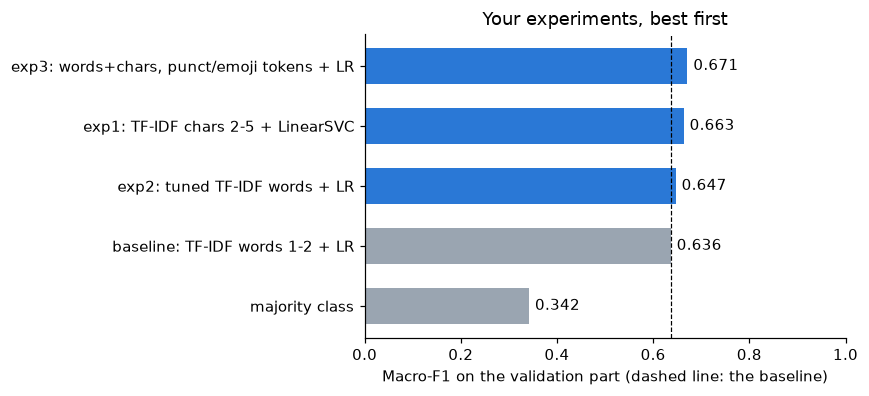

In [19]:
table = pd.DataFrame({name: r["scores"] for name, r in results.items()}).T
table["notes"] = [results[n]["notes"] for n in table.index]
table = table.sort_values("macro_f1", ascending=False)
display(table.style.format({c: "{:.3f}" for c in table.columns if c != "notes"}))

fig, ax = plt.subplots(figsize=(8, 0.5 * len(table) + 1.2))
colors = [BLUE if "baseline" not in n and "majority" not in n else GREY for n in table.index]
bars = ax.barh(table.index, table["macro_f1"], color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in table["macro_f1"]], padding=4)
ax.axvline(results["baseline: TF-IDF words 1-2 + LR"]["scores"]["macro_f1"], color="black", lw=0.8, ls="--")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Macro-F1 on the validation part (dashed line: the baseline)")
ax.set_title("Your experiments, best first")
plt.tight_layout()
plt.show()

**How to read it:** one bar per logged run, the length is its macro-F1 on the validation part; the dashed line is the baseline you must beat. Grey bars are the two baselines. Remember the noise floor from section 6: a difference smaller than the cross-validation spread is not a result, it is a coin toss. Say so in your report when it applies.

Optional, for the pretrained-model route (not run in this notebook). On Colab with a GPU, `pip install transformers datasets accelerate`, then roughly:

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
name = "distilroberta-base"                      # or cardiffnlp/twitter-roberta-base; never an irony-tuned model
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
enc = lambda batch: tok(batch["text"], truncation=True, max_length=64)
# build a datasets.Dataset from X_train / y_train and X_val / y_val, map enc over it, then:
args = TrainingArguments("out", learning_rate=2e-5, num_train_epochs=3, per_device_train_batch_size=32,
                         eval_strategy="epoch", seed=SEED, report_to=[])
Trainer(model=model, args=args, train_dataset=..., eval_dataset=..., processing_class=tok).train()
```

Evaluate it with the same `evaluate` helper on the same validation part so the comparison with your classical models is fair, and log it in `results` by hand.

## 8. Error analysis (required)

> **Error analysis**, in plain words: reading the tweets your model got wrong, sorting them into kinds of mistake, and deciding what to change. It is the most valuable hour of any machine learning project, and the part most people skip.

The cell picks your best logged run (by validation macro-F1), draws its confusion matrix, and prints the eight **false alarms** (non-ironic tweets called ironic) and the eight **misses** (ironic tweets called not ironic) the model was most confident about. Confident errors are the interesting ones: they show what the model believes.

best run on validation: exp3: words+chars, punct/emoji tokens + LR | macro-F1 0.671


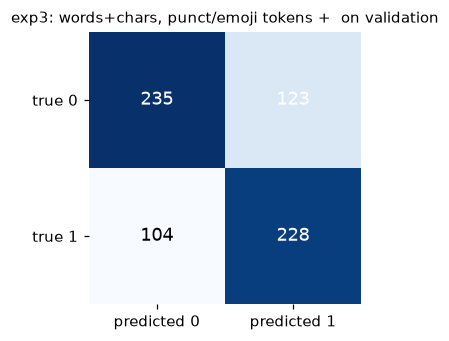


123 false alarms, 104 misses. The most confident eight of each:

FALSE ALARMS (truth: not ironic, model: ironic)
  +2.87  @user @user your Irish fans can't wait.... Impossible to get ticket ... Boo hoo!
  +2.62  So glad to be off work
  +2.31  i feel like whole life is about waiting waiting and waiting
  +2.30  Heartless Sanghi #Sarcasm"@Retributions: #IndiawithPakistan because a dumb nation deserves to be taken for a r
  +2.06  @user Saturday at 11:00?  Damn...there goes my secret news paraphernalia....   telling
  +1.98  Can't wait until this weekend is over...then no more Xmas parties!!!!!! #HateSchmoozing
  +1.80  @user @user @user @user @user @user nice what you cooking me😜😜
  +1.71  @user So when Tory stood up and thanked Ford for his service to the city, I wanted to barf.

MISSES (truth: ironic, model: not ironic)
  -2.93  @user i wanna do mine but im a pussy
  -2.91  @user actually cropped out her daughter in this pic for a selfie 🙈 #topmum
  -2.87  I hate plane rides but I wa

In [20]:
best_name = max((n for n in results if "majority" not in n), key=lambda n: results[n]["scores"]["macro_f1"])
best = results[best_name]["model"]
print("best run on validation:", best_name, "| macro-F1", round(results[best_name]["scores"]["macro_f1"], 3))

val = pd.DataFrame({"text": X_val.values, "true": y_val.values, "pred": best.predict(X_val)})
if hasattr(best, "decision_function"):
    val["score"] = best.decision_function(X_val)             # > 0 means the model leans ironic
else:
    val["score"] = best.predict_proba(X_val)[:, 1] - 0.5
plot_confusion(val["true"], val["pred"], f"{best_name[:40]} on validation")

false_alarms = val[(val["true"] == 0) & (val["pred"] == 1)].sort_values("score", ascending=False)
misses = val[(val["true"] == 1) & (val["pred"] == 0)].sort_values("score")
print(f"\n{len(false_alarms)} false alarms, {len(misses)} misses. The most confident eight of each:\n")
print("FALSE ALARMS (truth: not ironic, model: ironic)")
for _, r in false_alarms.head(8).iterrows():
    print(f"  {r.score:+.2f}  {r.text[:110]}")
print("\nMISSES (truth: ironic, model: not ironic)")
for _, r in misses.head(8).iterrows():
    print(f"  {r.score:+.2f}  {r.text[:110]}")

**Your error analysis (TODO).** Read at least ten errors of each kind (change `.head(8)` or sample at random) and answer, in five to ten sentences here:

1. What kinds of tweets fool the model? Group the errors (for example: positive words about a bad situation with no explicit clue; irony that needs world knowledge; a hashtag that carries the whole meaning; non-ironic tweets that merely sound enthusiastic; annotation you disagree with).
2. Which kind is most frequent, and is it fixable with features you can compute, or does it need a model that understands context?
3. Pick one kind and try one fix (a feature, a preprocessing switch, a model). Log it as an experiment in section 7 and report whether it helped.

_Your analysis here._

## 9. Train the final model and write your submission

Choosing is over. The cell takes your best run (change `FINAL_MODEL_NAME` if you prefer another one and say why in the report), **refits it on all of `train.csv`** so that it learns from every labelled tweet, predicts `test.csv`, and writes `submission.csv` in the required format: one row per test id, label 0 or 1. The checks after it are the same ones the grader runs; fix anything they flag.

In [21]:
FINAL_MODEL_NAME = best_name          # or any other key of `results`
final_model = clone(results[FINAL_MODEL_NAME]["model"]).fit(train["text"], train["label"])
test_pred = final_model.predict(test["text"])

submission = pd.DataFrame({"id": test["id"], "label": test_pred.astype(int)})
submission.to_csv("submission.csv", index=False)

check = pd.read_csv("submission.csv")
assert list(check.columns) == ["id", "label"], check.columns
assert len(check) == len(test) and set(check["id"]) == set(test["id"]), "ids must match test.csv exactly"
assert set(check["label"].unique()) <= {0, 1}, "labels must be 0 or 1"
print(f"final model: {FINAL_MODEL_NAME}")
print(f"submission.csv written: {len(check):,} rows, {check['label'].mean():.1%} predicted ironic "
      f"(training share was {train['label'].mean():.1%})")
check.head()

final model: exp3: words+chars, punct/emoji tokens + LR
submission.csv written: 1,151 rows, 48.3% predicted ironic (training share was 48.1%)


,id,label
0,te0000,0
1,te0001,1
2,te0002,1
3,te0003,1
4,te0004,1


## 10. Your report (fill in)

Write it here, in this notebook, in plain language; a reader who has not seen your code should understand what you did and what you found. Aim for 400 to 700 words plus your results table.

**Approach.** Which features, preprocessing and models you tried, in what order, and why.

**Results.** Your results table from section 7 (copy it or refer to it), the cross-validation spread of your best model, and the one you submitted. If two runs were within the noise, say so.

**What the model learned.** Two or three findings from the exploration and the model weights.

**Error analysis.** The kinds of mistakes, their frequency, the fix you tried and its effect.

**Limitations and ethics.** Where would this model be wrong in ways that matter? Think about: the data comes from writers who tagged their own irony, so the corpus may not look like irony in general; the tweets are English and from one period; a moderation tool that misreads irony flags the wrong people; a model that detects irony about a product or a politician can be used to silence it. One paragraph, specific to what you observed.

**Use of AI assistants.** State which tools you used, for what, and confirm that you can explain every line of this notebook. Not using any is fine; hiding it is not.

**References.** The dataset paper, the TweetEval paper, any pretrained model, any tutorial you followed.

## Checklist before you hand in

- Kernel > Restart & Run All completes without an error, with the data files in `data/`.
- Section 3 has at least two analyses of your own, each with an interpretation.
- Section 7 has at least three experiments beyond the baselines, all in the results table, one change at a time.
- Section 8 answers the three questions with at least ten errors of each kind read.
- `submission.csv` exists, passes the checks in section 9, and comes from the model your report names.
- Section 10 is written, including limitations, ethics and the AI-use statement.
- The notebook and `submission.csv` are both named with your name or student number, as the guidelines ask.

## References

- Van Hee, C., Lefever, E. and Hoste, V. (2018). *SemEval-2018 Task 3: Irony Detection in English Tweets.* Proceedings of the 12th International Workshop on Semantic Evaluation, pages 39 to 50. [aclanthology.org/S18-1005](https://aclanthology.org/S18-1005/)
- Barbieri, F., Camacho-Collados, J., Espinosa-Anke, L. and Neves, L. (2020). *TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification.* Findings of EMNLP 2020. Data: [github.com/cardiffnlp/tweeteval](https://github.com/cardiffnlp/tweeteval) (irony task); Kaggle mirror: [TweetEval (Multi-task Classification Benchmark)](https://www.kaggle.com/datasets/thedevastator/tweeteval-a-multi-task-classification-benchmark).
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12. The user guide on [working with text data](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html) is the best next read.